In [1]:
# Import required modules
from map import app
import requests
import json
import os
import geopandas as gpd
import shapely as shp
from shapely.ops import unary_union
import matplotlib.pyplot as plt

In [2]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print('{}{}/'.format(indent, os.path.basename(root)))
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print('{}{}'.format(subindent, f))

In [3]:
list_files(startpath="C:/IMAGE/Foliage/image_api/")

/
    ~$AGE - User Guide.docx
    ~WRL0005.tmp
data/
    cps.db
    subgrids.db
    .vs/
        slnx.sqlite
        VSWorkspaceState.json
        data/
            v15/
                .ssms_suo
map_app/
polygons/
    another_1.dbf
    another_1.shp
    another_1.shx
    blr_1.cpg
    blr_1.dbf
    blr_1.shp
    blr_1.shx
    blr_2.dbf
    blr_2.prj
    blr_2.shp
    blr_2.shx
    blr_3.dbf
    blr_3.prj
    blr_3.shp
    blr_3.shx
    del_1.dbf
    del_1.prj
    del_1.shp
    del_1.shx
    mum_1.dbf
    mum_1.prj
    mum_1.shp
    mum_1.shx
    mum_2.dbf
    mum_2.prj
    mum_2.shp
    mum_2.shx
    mum_3.dbf
    mum_3.prj
    mum_3.shp
    mum_3.shx
preprocess/
    cellSector_to_shp.ipynb
    convert_subgrid.py
    database_create.ipynb
    dataset_centroids.json
    Elevation_Trial.ipynb
    get_cell_poly.ipynb
    nearest_cluster.ipynb
sql_app/
    api_testing.ipynb
    cps.db
    crud.py
    database_sql.py
    functions_map.py
    main.py
    map.ipynb
    map.py
    map_old.py


In [4]:
## Set parameters for API
cpu_count = 4
API_LINK = 'http://127.0.0.5:8000'
api_geodata = "/geodata/"

In [ ]:
## Define functions
def wkt_to_boundary(poly_list: list):
    #list_polygons =  [shp.wkt.loads(poly) for poly in poly_wkt]
    #list_polygons = [shp.wkt.loads(poly_wkt)]
    poly_multi = shp.geometry.MultiPolygon(poly_list)
    poly = poly_multi.convex_hull
    boundary = unary_union(poly)

    #import matplotlib.pyplot as plt
    #plt.plot(*boundary.exterior.xy)
    #print(boundary)

    return boundary



def getCoordinatesFromPolygon(path_shape: str):
    """Extracts the boundary of a polygon in the form of a string.

    Args:
        path_shape (str): Path of the polygon file. Must be a shapefile (.shp).

    Returns:
        str: Comma-separated string of polygon coordinates.
    """
    if path_shape=="":
        return "WARNING: No filepath given."
    try:
        gdf = gpd.read_file(path_shape)
    except FileNotFoundError:
        return "WARNING: File not found."
    except Exception as e:
        return "WARNING: An error occured - ", e
    
    for shape in gdf['geometry']:
        if isinstance(shape, shp.geometry.Polygon) != True:
            return "WARNING: The file contains non-polygon element(s). Please ensure all components are of polygon type only."
    
    poly_list = []
    for i in gdf.index:
        poly_list.append(gdf['geometry'][i])
        #print(gdf['geometry'][i])
    #print("L: ", len(poly_list))
    print("Poly List: ", poly_list)
    print("Length of poly list: ", len(poly_list))
    o_xx, o_yy = gdf['geometry'][0].exterior.coords.xy
    origin = (o_xx.tolist()[0], o_yy.tolist()[0])
    #print(origin)

    boundary = wkt_to_boundary(poly_list)
    print("Boundary: ", boundary, type(boundary))

    boundary_list = list(boundary.exterior.coords)
    poly_str = ""

    print("Boundary list: ", boundary_list, type(boundary_list))

    union_polygon = gdf.geometry.unary_union
    if isinstance(union_polygon, shp.geometry.Polygon):
        #print("DEBUGGING")
        union_polygon = shp.geometry.MultiPolygon([union_polygon])
    #gpd.GeoSeries(union_polygon).plot()
    print("Type of union polygon: ", type(union_polygon))

    boundary_list = [list(polygon.exterior.coords)[:-1] for polygon in list(union_polygon.geoms)]   
    #print(boundary_list)

    # Trial of poly
    temp = []
    for l in boundary_list:
        for coords in l:
            temp.append(coords)

    #temp_poly = shp.Polygon(temp)
    plt.plot(*boundary.exterior.xy)
    print(boundary.exterior.xy)



    for l in boundary_list:
        for coords in l:
            poly_str+=str(coords[0])+str(',')+str(coords[1])
            poly_str+=','
        poly_str+=str(origin[0])+str(',')+str(origin[1])
        poly_str+=','
    #print(poly_str)

    poly_str = poly_str[:-1]

    return poly_str

    ''''poly = gdf['geometry'][0]

    poly_list = list(poly.exterior.coords)
    poly_str = ""

    for c in poly_list[:-2]:
        for l in c:
            poly_str+=str(l)
            poly_str+=','
    
    poly_str = poly_str[:-1]

    return poly_str'''
    


def queryApiForGeodata(path_shape, location="", option_getStats=True):
    """Queries the API and gets a JSON response.

    Args:
        path_shape (str): Path of the polygon file. Must be a shapefile (.shp).
        location (str, optional): Name of desired geographic location (city) provided as part of the initial API call. 
                        If no location given (==""), API automatically determines the most appropriate cluster. 
                        Defaults to "".
        option_getStats (bool, optional): Provides option to include statistics like area, % cover. 
                                            Defaults to True.

    Returns:
        dict: Dictionary containing the geodata.
    """    
    input_str = getCoordinatesFromPolygon(path_shape=path_shape)

    payload = {
        'input_str': input_str,
        'location': location,
        'option_getStats': option_getStats
    }

    response = requests.get(
        url=API_LINK+api_geodata,
        params=payload
    )

    if response.status_code == 200:
        data = response.json()
        #print(data)
    else:
        print("Failed to retrieve data", response.status_code)
    
    return json.loads(response.text)

In [6]:
## List all polygon files
PATH = "C:/IMAGE/Foliage/image_api/polygons/"
dir_list = os.listdir(PATH)

print("Polygon shapefiles in '", PATH, "':")

for f in dir_list:
    if f.endswith('.shp'):
        print(f)

Polygon shapefiles in ' C:/IMAGE/Foliage/image_api/polygons/ ':
another_1.shp
blr_1.shp
blr_2.shp
blr_3.shp
del_1.shp
mum_1.shp
mum_2.shp
mum_3.shp


0    POLYGON ((72.88849 19.27182, 72.89461 19.27871...
1    POLYGON ((72.88849 19.27182, 72.89325 19.26403...
2    POLYGON ((72.88849 19.27182, 72.87911 19.27026...
Name: geometry, dtype: geometry
Poly List:  [<POLYGON ((72.888 19.272, 72.895 19.279, 72.896 19.277, 72.897 19.275, 72.89...>, <POLYGON ((72.888 19.272, 72.893 19.264, 72.891 19.263, 72.888 19.263, 72.88...>, <POLYGON ((72.888 19.272, 72.879 19.27, 72.879 19.273, 72.88 19.275, 72.881 ...>]
Length of poly list:  3
Boundary:  POLYGON ((72.88849 19.262825796645075, 72.88602434408767 19.263132216090888, 72.88372669244535 19.26403059575044, 72.87910775915437 19.270257107300814, 72.8789991401507 19.27260256441336, 72.87953731661693 19.27489463877746, 72.88068563722776 19.27697712392384, 72.88236586135086 19.27870809147847, 72.89461413864915 19.27870809147847, 72.89629436277224 19.27697712392384, 72.89744268338308 19.27489463877746, 72.89798085984931 19.27260256441336, 72.89787224084564 19.270257107300814, 72.89325330755466 19.264

{'Polygon geodata': [{'IMAGE_NAME': 'Mumbai.734.tif',
   'PT_LAT': 19.27718008,
   'PT_LON': 72.88129184,
   'BUILD_PROB': 0.9999893,
   'FOLIAGE_PROB': 0.000213802,
   'CLASS': 'Building',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.734.tif',
   'PT_LAT': 19.2767561,
   'PT_LON': 72.88084268,
   'BUILD_PROB': 0.97664183,
   'FOLIAGE_PROB': 0.03463844,
   'CLASS': 'Building',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.734.tif',
   'PT_LAT': 19.2767561,
   'PT_LON': 72.88129184,
   'BUILD_PROB': 0.42030397,
   'FOLIAGE_PROB': 0.014431159,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.734.tif',
   'PT_LAT': 19.27633213,
   'PT_LON': 72.88039352,
   'BUILD_PROB': 0.005877671,
   'FOLIAGE_PROB': 0.29390478,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.734.tif',
   'PT_LAT': 19.27633213,
   'PT_LON': 72.88084268,
   'BUILD_PROB': 0.22374302,
   'FOLIAGE_PROB': 0.94088894,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.734

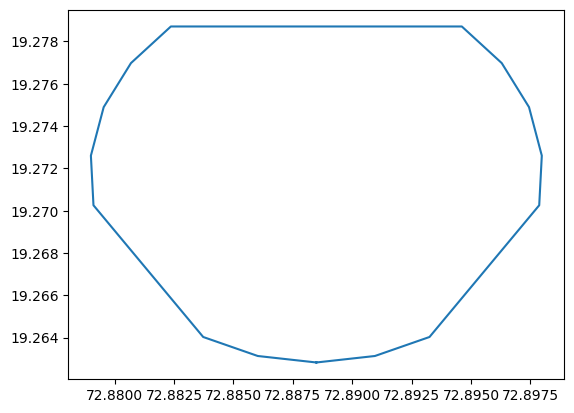

In [23]:
## TESTING SITE FILES
SHAPE = 'I-MH-ABAD-ENB-6000.shp'
location = ""
option_getStats = True
queryApiForGeodata(path_shape="C:/IMAGE/Foliage/image_api_docs/shapefiles/"+SHAPE, location=location, option_getStats=option_getStats)

In [8]:
#a=

0    POLYGON ((77.57656 12.98234, 77.57656 12.98234...
Name: geometry, dtype: geometry
Poly List:  [<POLYGON ((77.577 12.982, 77.577 12.982, 77.584 12.988, 77.594 12.986, 77.59...>]
Length of poly list:  1
Boundary:  POLYGON ((77.58818870107149 12.966908924297899, 77.5782323412082 12.974352950096858, 77.57655864278291 12.98234039287252, 77.58424048940157 12.987776725438124, 77.59385352651094 12.985560388830299, 77.59707217732881 12.981253112087616, 77.59938960591768 12.976903941387736, 77.58818870107149 12.966908924297899)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(77.58818870107149, 12.966908924297899), (77.5782323412082, 12.974352950096858), (77.57655864278291, 12.98234039287252), (77.58424048940157, 12.987776725438124), (77.59385352651094, 12.985560388830299), (77.59707217732881, 12.981253112087616), (77.59938960591768, 12.976903941387736), (77.58818870107149, 12.966908924297899)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolyg

{'Polygon geodata': [{'IMAGE_NAME': 'Bangalore.2375.tif',
   'PT_LAT': 12.98753711,
   'PT_LON': 77.58423078,
   'BUILD_PROB': 0.002356375,
   'FOLIAGE_PROB': 0.71765816,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.2375.tif',
   'PT_LAT': 12.98753711,
   'PT_LON': 77.58467993,
   'BUILD_PROB': 0.00063417,
   'FOLIAGE_PROB': 0.7192588,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.2375.tif',
   'PT_LAT': 12.98753711,
   'PT_LON': 77.58512909,
   'BUILD_PROB': 0.000592442,
   'FOLIAGE_PROB': 0.8804488,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.2375.tif',
   'PT_LAT': 12.98709944,
   'PT_LON': 77.58333246,
   'BUILD_PROB': 0.94330555,
   'FOLIAGE_PROB': 0.025281254,
   'CLASS': 'Building',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.2375.tif',
   'PT_LAT': 12.98709944,
   'PT_LON': 77.58378162,
   'BUILD_PROB': 0.015782028,
   'FOLIAGE_PROB': 0.79495704,
   'CLASS': 'Foliage',
   'overlap': True},
  {

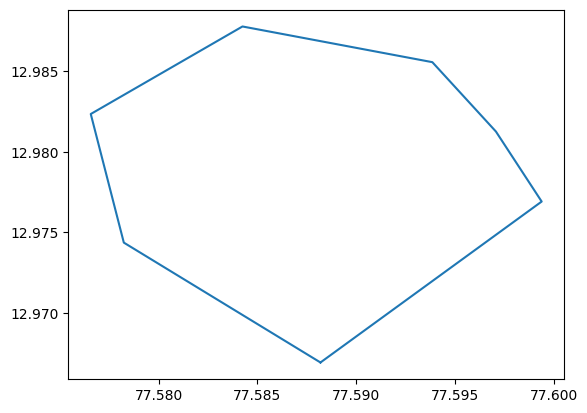

In [22]:
# BLR polygon; No location;
SHAPE = 'blr_1.shp'
location = ""
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((77.52 13.066, 77.529 13.062, 77.533 13.055, 77.535 13.055, 77.535...>]
Length of poly list:  1
Boundary:  POLYGON ((77.54088145069797 13.029119643153981, 77.53125627775243 13.032943341995358, 77.5197851812283 13.048238137360858, 77.51925777449159 13.049292950834339, 77.51671962957103 13.05819293951685, 77.51899407112323 13.065016264173444, 77.5289488732792 13.072103292198408, 77.54305700348705 13.078827728091863, 77.55373698990606 13.07605884272397, 77.56685623248251 13.055358128306867, 77.56369179206206 13.045601103677152, 77.56151623927299 13.039931481257181, 77.54088145069797 13.029119643153981)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(77.54088145069797, 13.029119643153981), (77.53125627775243, 13.032943341995358), (77.5197851812283, 13.048238137360858), (77.51925777449159, 13.049292950834339), (77.51671962957103, 13.05819293951685), (77.51899407112323, 13.065016264173444), (77.5289488732792, 13.072103292198408), (77.54305700348705, 13.07

{'Polygon geodata': [{'IMAGE_NAME': 'Bangalore.1035.tif',
   'PT_LAT': 13.06499228,
   'PT_LON': 77.51910285,
   'BUILD_PROB': 0.000257722,
   'FOLIAGE_PROB': 0.98957205,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.1035.tif',
   'PT_LAT': 13.06499228,
   'PT_LON': 77.51955201,
   'BUILD_PROB': 0.000468963,
   'FOLIAGE_PROB': 0.9908935,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.1035.tif',
   'PT_LAT': 13.06499228,
   'PT_LON': 77.52000116,
   'BUILD_PROB': 0.000658352,
   'FOLIAGE_PROB': 0.9864007,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.1035.tif',
   'PT_LAT': 13.06499228,
   'PT_LON': 77.52045032,
   'BUILD_PROB': 0.000485519,
   'FOLIAGE_PROB': 0.9790324,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Bangalore.1035.tif',
   'PT_LAT': 13.06499228,
   'PT_LON': 77.52089948,
   'BUILD_PROB': 0.000472956,
   'FOLIAGE_PROB': 0.97186285,
   'CLASS': 'Foliage',
   'overlap': True},
  {'

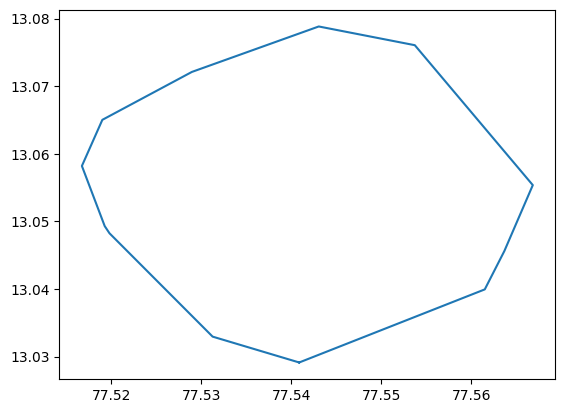

In [10]:
# BLR polygon; Location given
SHAPE = 'blr_3.shp'
location = "bangalore"
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((77.608 12.999, 77.63 12.979, 77.626 12.976, 77.604 12.984, 77.6 1...>]
Length of poly list:  1
Boundary:  POLYGON ((77.626255416208 12.976378969479834, 77.60430211079112 12.984290070530955, 77.60047841194975 13.001035234422497, 77.60786210626414 12.998530052422975, 77.62988133752309 12.979016003163542, 77.626255416208 12.976378969479834)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(77.626255416208, 12.976378969479834), (77.60430211079112, 12.984290070530955), (77.60047841194975, 13.001035234422497), (77.60786210626414, 12.998530052422975), (77.62988133752309, 12.979016003163542), (77.626255416208, 12.976378969479834)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [77.626255416208, 77.60430211079112, 77.60047841194975, 77.60786210626414, 77.62988133752309, 77.626255416208]), array('d', [12.976378969479834, 12.984290070530955, 13.001035234422497, 12.998530052422975, 12.97901600316

"WARNING: No data for given polygon. Check to make sure that it's of a location with geodata present in the database."

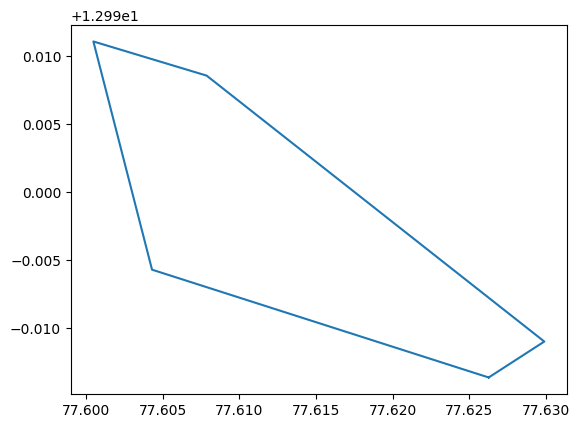

In [11]:
# BLR polygon; Incorrect location
SHAPE = 'blr_2.shp'
location = "mumbai"
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((73.001 19.038, 73.095 19.037, 73.099 18.97, 73.034 18.945, 73.011...>]
Length of poly list:  1
Boundary:  POLYGON ((73.01116305727406 18.943506588624146, 73.00117785870015 19.037923749549037, 73.09474883243323 19.037162535147946, 73.09909722536058 18.970009711281943, 73.03354922827046 18.94457288748248, 73.01116305727406 18.943506588624146)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(73.01116305727406, 18.943506588624146), (73.00117785870015, 19.037923749549037), (73.09474883243323, 19.037162535147946), (73.09909722536058, 18.970009711281943), (73.03354922827046, 18.94457288748248), (73.01116305727406, 18.943506588624146)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [73.01116305727406, 73.00117785870015, 73.09474883243323, 73.09909722536058, 73.03354922827046, 73.01116305727406]), array('d', [18.943506588624146, 19.037923749549037, 19.037162535147946, 18.970009711281943, 18.9

{'Polygon geodata': [{'IMAGE_NAME': 'Mumbai.5185.tif',
   'PT_LAT': 19.03788369,
   'PT_LON': 73.00121737,
   'BUILD_PROB': 0.23090327,
   'FOLIAGE_PROB': 0.003201873,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.5185.tif',
   'PT_LAT': 19.03788369,
   'PT_LON': 73.00166652,
   'BUILD_PROB': 0.16883573,
   'FOLIAGE_PROB': 0.12287712,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.5185.tif',
   'PT_LAT': 19.03788369,
   'PT_LON': 73.00211568,
   'BUILD_PROB': 0.052467257,
   'FOLIAGE_PROB': 0.95546377,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.5185.tif',
   'PT_LAT': 19.03788369,
   'PT_LON': 73.00256484,
   'BUILD_PROB': 0.036679942,
   'FOLIAGE_PROB': 0.9937018,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Mumbai.5186.tif',
   'PT_LAT': 19.03788369,
   'PT_LON': 73.00301401,
   'BUILD_PROB': 0.009072284,
   'FOLIAGE_PROB': 0.9957982,
   'CLASS': 'Foliage',
   'overlap': True},
  {'IMAGE_NAME': 'Mumba

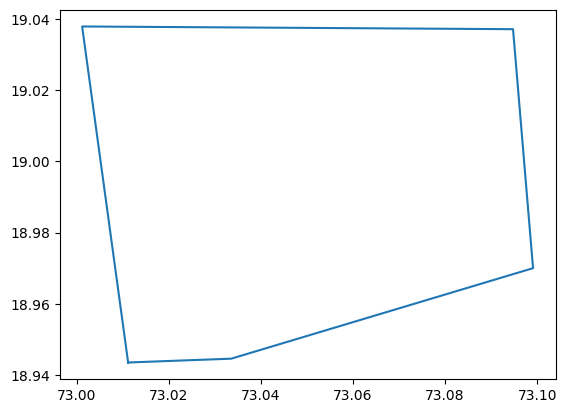

In [12]:
# MUM polygon; No stats
SHAPE = 'mum_1.shp'
location = ""
option_getStats = False
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((76.963 28.628, 77.222 28.627, 77.223 28.484, 76.965 28.482, 76.96...>]
Length of poly list:  1
Boundary:  POLYGON ((76.96526363260307 28.482092313453975, 76.96278949972773 28.627695193860017, 77.22207862506285 28.627260858199612, 77.22257345163791 28.483614577910636, 76.96526363260307 28.482092313453975)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(76.96526363260307, 28.482092313453975), (76.96278949972773, 28.627695193860017), (77.22207862506285, 28.627260858199612), (77.22257345163791, 28.483614577910636), (76.96526363260307, 28.482092313453975)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [76.96526363260307, 76.96278949972773, 77.22207862506285, 77.22257345163791, 76.96526363260307]), array('d', [28.482092313453975, 28.627695193860017, 28.627260858199612, 28.483614577910636, 28.482092313453975]))


{'Polygon geodata': [{'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09426784745685,
   'BUILD_PROB': 0.0736914,
   'FOLIAGE_PROB': 0.0073519107,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09471700509891,
   'BUILD_PROB': 0.03447124,
   'FOLIAGE_PROB': 0.02891218,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09516616274097,
   'BUILD_PROB': 0.07762634,
   'FOLIAGE_PROB': 0.0044729346,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09561532038303,
   'BUILD_PROB': 0.003687166,
   'FOLIAGE_PROB': 0.004213831,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09606447802508,
   'BUILD_PROB': 0.0063712425,
   'FOLIAGE_PROB': 0.005219462,


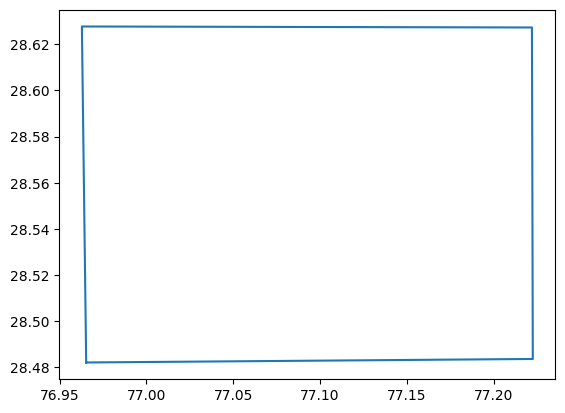

In [13]:
# DEL polygon; 
SHAPE = 'del_1.shp'
location = ""
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((76.963 28.628, 77.222 28.627, 77.223 28.484, 76.965 28.482, 76.96...>]
Length of poly list:  1
Boundary:  POLYGON ((76.96526363260307 28.482092313453975, 76.96278949972773 28.627695193860017, 77.22207862506285 28.627260858199612, 77.22257345163791 28.483614577910636, 76.96526363260307 28.482092313453975)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(76.96526363260307, 28.482092313453975), (76.96278949972773, 28.627695193860017), (77.22207862506285, 28.627260858199612), (77.22257345163791, 28.483614577910636), (76.96526363260307, 28.482092313453975)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [76.96526363260307, 76.96278949972773, 77.22207862506285, 77.22257345163791, 76.96526363260307]), array('d', [28.482092313453975, 28.627695193860017, 28.627260858199612, 28.483614577910636, 28.482092313453975]))


{'Polygon geodata': [{'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09426784745685,
   'BUILD_PROB': 0.0736914,
   'FOLIAGE_PROB': 0.0073519107,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09471700509891,
   'BUILD_PROB': 0.03447124,
   'FOLIAGE_PROB': 0.02891218,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09516616274097,
   'BUILD_PROB': 0.07762634,
   'FOLIAGE_PROB': 0.0044729346,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09561532038303,
   'BUILD_PROB': 0.003687166,
   'FOLIAGE_PROB': 0.004213831,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09606447802508,
   'BUILD_PROB': 0.0063712425,
   'FOLIAGE_PROB': 0.005219462,


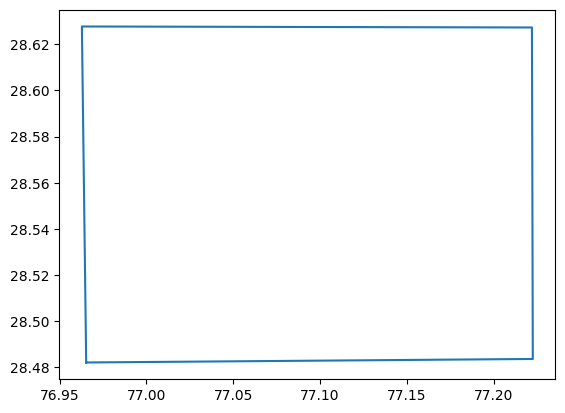

In [14]:
# DEL polygon; polygon data empty
SHAPE = 'del_1.shp'
location = ""
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

In [15]:
# Incomplete polygon (missing coordinates)
SHAPE = 'del_1.shp'
location = ""
option_getStats = True
queryApiForGeodata(input_str="77.5921810342194078,12.9681468317523088,\
                   77.5921810342194078,12.9713170621197271,\
                   77.5948604757851683,12.9713170621197271,\
                   77.5948604757851683", 
                   location=location, option_getStats=option_getStats)

TypeError: queryApiForGeodata() got an unexpected keyword argument 'input_str'

In [16]:
# Incomplete polygon (<3 points)
SHAPE = 'del_1.shp'

location = ""
option_getStats = True
queryApiForGeodata(input_str="77.5921810342194078,12.9681468317523088,\
                   77.5921810342194078,12.9713170621197271",
                   location=location, option_getStats=option_getStats)

TypeError: queryApiForGeodata() got an unexpected keyword argument 'input_str'

In [17]:
# Incomplete polygon (<3 points, missing coordinates)
SHAPE = 'del_1.shp'

location = ""
option_getStats = True
queryApiForGeodata(input_str="77.5921810342194078,12.9681468317523088,\
                   77.5921810342194078",
                   location=location, option_getStats=option_getStats)

TypeError: queryApiForGeodata() got an unexpected keyword argument 'input_str'

Poly List:  [<POLYGON ((76.963 28.628, 77.222 28.627, 77.223 28.484, 76.965 28.482, 76.96...>]
Length of poly list:  1
Boundary:  POLYGON ((76.96526363260307 28.482092313453975, 76.96278949972773 28.627695193860017, 77.22207862506285 28.627260858199612, 77.22257345163791 28.483614577910636, 76.96526363260307 28.482092313453975)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(76.96526363260307, 28.482092313453975), (76.96278949972773, 28.627695193860017), (77.22207862506285, 28.627260858199612), (77.22257345163791, 28.483614577910636), (76.96526363260307, 28.482092313453975)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [76.96526363260307, 76.96278949972773, 77.22207862506285, 77.22257345163791, 76.96526363260307]), array('d', [28.482092313453975, 28.627695193860017, 28.627260858199612, 28.483614577910636, 28.482092313453975]))


{'Polygon geodata': [{'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09426784745685,
   'BUILD_PROB': 0.0736914,
   'FOLIAGE_PROB': 0.0073519107,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09471700509891,
   'BUILD_PROB': 0.03447124,
   'FOLIAGE_PROB': 0.02891218,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09516616274097,
   'BUILD_PROB': 0.07762634,
   'FOLIAGE_PROB': 0.0044729346,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09561532038303,
   'BUILD_PROB': 0.003687166,
   'FOLIAGE_PROB': 0.004213831,
   'CLASS': 'Other',
   'overlap': True},
  {'IMAGE_NAME': 'Delhi.10000.tif',
   'PT_LAT': 28.532444521669067,
   'PT_LON': 77.09606447802508,
   'BUILD_PROB': 0.0063712425,
   'FOLIAGE_PROB': 0.005219462,


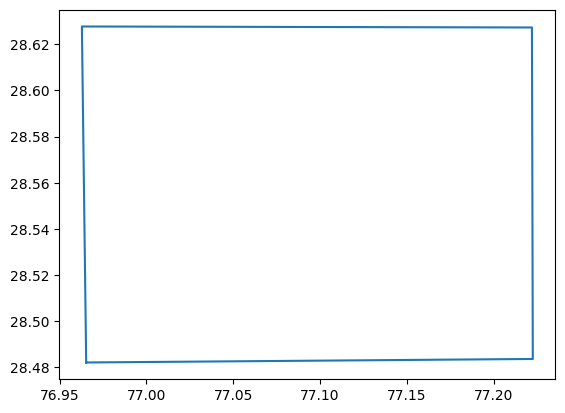

In [18]:
# DEL polygon; location name slightly misspelt
SHAPE = 'del_1.shp'
location = "Dlhi"
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((76.963 28.628, 77.222 28.627, 77.223 28.484, 76.965 28.482, 76.96...>]
Length of poly list:  1
Boundary:  POLYGON ((76.96526363260307 28.482092313453975, 76.96278949972773 28.627695193860017, 77.22207862506285 28.627260858199612, 77.22257345163791 28.483614577910636, 76.96526363260307 28.482092313453975)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(76.96526363260307, 28.482092313453975), (76.96278949972773, 28.627695193860017), (77.22207862506285, 28.627260858199612), (77.22257345163791, 28.483614577910636), (76.96526363260307, 28.482092313453975)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [76.96526363260307, 76.96278949972773, 77.22207862506285, 77.22257345163791, 76.96526363260307]), array('d', [28.482092313453975, 28.627695193860017, 28.627260858199612, 28.483614577910636, 28.482092313453975]))


'WARNING: Location name not recognized. Check for typos, or if location present in database table.'

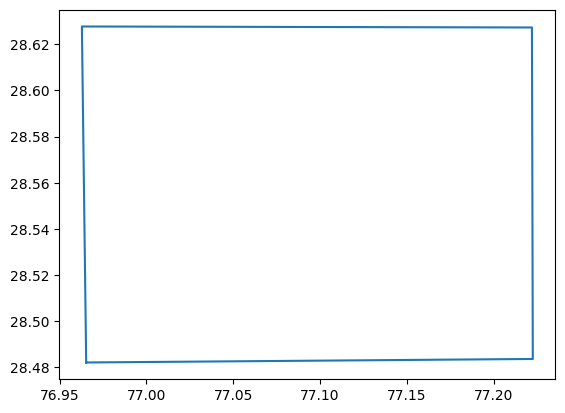

In [19]:
# DEL polygon; location name not in centroid dataset
SHAPE = 'del_1.shp'
location = "kolkata"
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

Poly List:  [<POLYGON ((77.466 26.109, 77.617 26.054, 77.535 26.028, 77.429 26.046, 77.37...>]
Length of poly list:  1
Boundary:  POLYGON ((77.53542755372405 26.02812823910974, 77.42903984008464 26.045912516216728, 77.37114513080179 26.110357899216467, 77.46615183321468 26.109469238743138, 77.61707393861012 26.054359102982886, 77.53542755372405 26.02812823910974)) <class 'shapely.geometry.polygon.Polygon'>
Boundary list:  [(77.53542755372405, 26.02812823910974), (77.42903984008464, 26.045912516216728), (77.37114513080179, 26.110357899216467), (77.46615183321468, 26.109469238743138), (77.61707393861012, 26.054359102982886), (77.53542755372405, 26.02812823910974)] <class 'list'>
DEBUGGING
Type of union polygon:  <class 'shapely.geometry.multipolygon.MultiPolygon'>
(array('d', [77.53542755372405, 77.42903984008464, 77.37114513080179, 77.46615183321468, 77.61707393861012, 77.53542755372405]), array('d', [26.02812823910974, 26.045912516216728, 26.110357899216467, 26.109469238743138, 26.0543

"WARNING: No data for given polygon. Check to make sure that it's of a location with geodata present in the database."

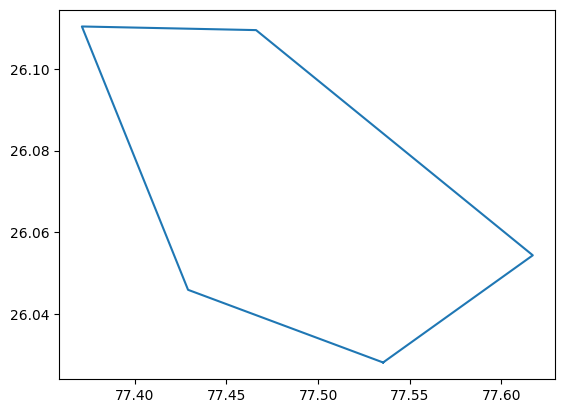

In [20]:
# Polygon for region whose geodata not in database
SHAPE = 'another_1.shp'
location = ""
option_getStats = True
queryApiForGeodata(path_shape=PATH+SHAPE, location=location, option_getStats=option_getStats)

In [ ]:
### JUNK CODE; WILL REMOVE
'''
client = TestClient(app)
from typing import List
response_model = List[Input]
print(response_model)

sf = shapefile.Reader(PATH+shape_name)

all_shapes = sf.shapes()
all_records = sf.records() 

for i in range(len(all_shapes)):
    boundary = SHAPE(all_shapes[i])
    print(boundary)

with open(PATH+SHAPE, "rb") as poly_file:
    loaded_polygon = pickle.load(poly_file)
    polygon_list = list(loaded_polygon.exterior.coords)
    return polygon_list
'''